## Project Overview & Problem Formulation
This notebook develops and evaluates Support Vector Machine (SVM) classifiers for binary medical diagnosis on the **Breast Cancer Wisconsin (Diagnostic)** dataset (`569` samples, `30` continuous morphological features). 

* **Clinical Objective:** Maximize **Recall (Sensitivity)** and **F1-score** for the positive class (`1 = Malignant`) to minimize False Negatives (missed malignant tumors), while maintaining high overall precision.
* **Target Encoding:** By default, `scikit-learn` encodes `malignant` as `0` and `benign` as `1`. In this workflow, the target labels are inverted so that **Malignant = 1 (Positive Class)** and **Benign = 0 (Negative Class)**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

In [2]:
data = load_breast_cancer()

In [3]:
X = pd.DataFrame(data.data, columns = data.feature_names)
y = pd.Series(data.target, name='target')

In [4]:
X.shape

(569, 30)

In [5]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [7]:
y.shape

(569,)

In [8]:
print(X.columns.tolist())

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [9]:
print(data.target_names)

['malignant' 'benign']


In [10]:
y.value_counts()
# 1 represents benign
# 0 represents malignant

target
1    357
0    212
Name: count, dtype: int64

In [11]:
X.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

In [12]:
y.isnull().sum()

np.int64(0)

In [13]:
# Set malignant as the positive class
y = pd.Series((data.target == 0).astype(int), name='target')

print("Target distribution:")
print(y.value_counts())

Target distribution:
target
0    357
1    212
Name: count, dtype: int64


## Data Splitting & Feature Scaling
* **Stratified Partitioning:** The dataset is split into `80%` training (`455` samples) and `20%` testing (`114` samples) using `stratify=y` (`random_state=1234`), preserving the exact class distribution (`63%` Benign, `37%` Malignant) across both subsets.
* **Standardization (`StandardScaler`):** Because SVM optimization relies on Euclidean distances in feature space and is sensitive to feature magnitudes, all 30 features are standardized to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$). The scaler is fitted strictly on `X_train` and applied to `X_test` to prevent data leakage.

In [14]:
# Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size= 0.2,
    random_state= 1234,
    stratify= y
)

In [15]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True).round(2))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True).round(2))

X_train shape: (455, 30)
X_test shape: (114, 30)

Training distribution:
target
0    0.63
1    0.37
Name: proportion, dtype: float64

Testing distribution:
target
0    0.63
1    0.37
Name: proportion, dtype: float64


In [16]:
from sklearn.preprocessing import StandardScaler

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nTraining feature means (first 5):")
print(X_train_scaled.mean(axis=0)[:5].round(4))

print("\nTraining feature standard deviations (first 5):")
print(X_train_scaled.std(axis=0)[:5].round(4))

X_train_scaled shape: (455, 30)
X_test_scaled shape: (114, 30)

Training feature means (first 5):
[-0.  0. -0. -0. -0.]

Training feature standard deviations (first 5):
[1. 1. 1. 1. 1.]


## Baseline Kernel Comparison ($C = 1.0$)
Three distinct SVM kernels are trained and evaluated on the standardized test set (`114` samples: `72` Benign, `42` Malignant) to establish baseline decision boundary behavior:

| Kernel Type | Hyperparameters | Accuracy | Precision (Malignant) | Recall (Malignant) | F1-Score (Malignant) | Key Diagnostic Observation |
| :--- | :--- | :---: | :---: | :---: | :---: | :--- |
| **Linear** | `C=1` | `0.9386` | `0.8889` | `0.9524` | `0.9195` | Strong baseline sensitivity; captures linear separability well. |
| **RBF (Radial Basis Function)** | `C=1, gamma='scale'` | `0.9737` | `0.9535` | `0.9762` | `0.9647` | Best baseline balance; captures non-linear feature interactions. |
| **Polynomial** | `C=1, degree=3, gamma='scale'` | `0.9386` | `1.0000` | `0.8333` | `0.9091` | Zero False Positives, but unacceptably low Recall (`83.3%`). |

In [18]:
from sklearn.svm import SVC

linear_svm = SVC(kernel='linear' , C =1)
linear_svm.fit(X_train_scaled,y_train)

y_pred_linear = linear_svm.predict(X_test_scaled)

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Linear SVM Results")
print("")
print("Accuracy:", accuracy_score(y_test, y_pred_linear))
print("Precision:", precision_score(y_test, y_pred_linear))
print("Recall:", recall_score(y_test, y_pred_linear))
print("F1-score:", f1_score(y_test, y_pred_linear))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_linear,
    target_names=['Benign', 'Malignant']
))

Linear SVM Results

Accuracy: 0.9385964912280702
Precision: 0.8888888888888888
Recall: 0.9523809523809523
F1-score: 0.9195402298850575

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.93      0.95        72
   Malignant       0.89      0.95      0.92        42

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



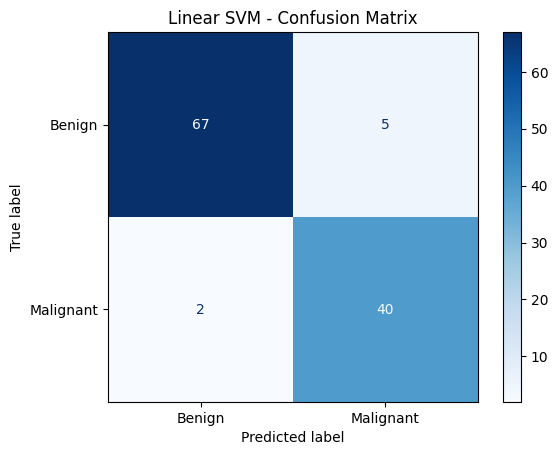

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_linear,
    display_labels=['Benign', 'Malignant'],
    cmap='Blues'
)

plt.title('Linear SVM - Confusion Matrix')
plt.show()

In [21]:
rbf_svm = SVC(kernel='rbf', C=1 , gamma='scale')
rbf_svm.fit(X_train_scaled,y_train)

y_pred_rbf = rbf_svm.predict(X_test_scaled)

In [22]:
print("RBF SVM Results")
print("")
print("Accuracy:", accuracy_score(y_test, y_pred_rbf))
print("Precision:", precision_score(y_test, y_pred_rbf))
print("Recall:", recall_score(y_test, y_pred_rbf))
print("F1-score:", f1_score(y_test, y_pred_rbf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rbf,
    target_names=['Benign', 'Malignant']
))

RBF SVM Results

Accuracy: 0.9736842105263158
Precision: 0.9534883720930233
Recall: 0.9761904761904762
F1-score: 0.9647058823529412

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.97      0.98        72
   Malignant       0.95      0.98      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



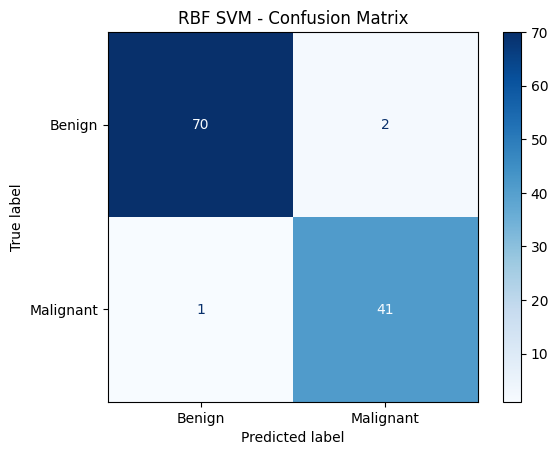

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rbf,
    display_labels=['Benign', 'Malignant'],
    cmap='Blues'
)

plt.title('RBF SVM - Confusion Matrix')
plt.show()

In [24]:
poly_svm = SVC(kernel='poly', C=1, degree=3 , gamma='scale')
poly_svm.fit(X_train_scaled,y_train)

y_pred_poly = poly_svm.predict(X_test_scaled)

In [25]:
print("Polynomial SVM Results")
print("")
print("Accuracy:", accuracy_score(y_test, y_pred_poly))
print("Precision:", precision_score(y_test, y_pred_poly))
print("Recall:", recall_score(y_test, y_pred_poly))
print("F1-score:", f1_score(y_test, y_pred_poly))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_poly,
    target_names=['Benign', 'Malignant']
))

Polynomial SVM Results

Accuracy: 0.9385964912280702
Precision: 1.0
Recall: 0.8333333333333334
F1-score: 0.9090909090909091

Classification Report:
              precision    recall  f1-score   support

      Benign       0.91      1.00      0.95        72
   Malignant       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



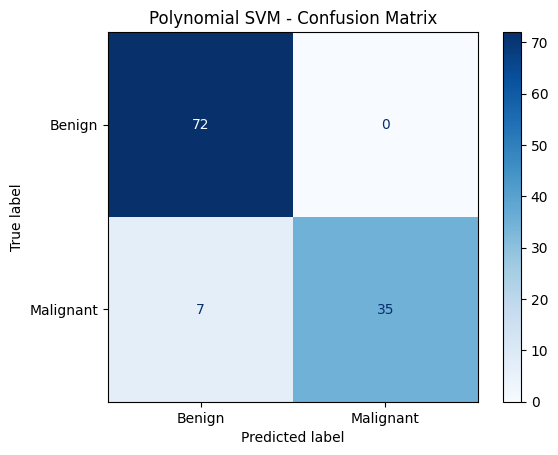

In [26]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_poly,
    display_labels=['Benign', 'Malignant'],
    cmap='Blues'
)

plt.title('Polynomial SVM - Confusion Matrix')
plt.show()

## Hyperparameter Tuning via Stratified 5-Fold Cross-Validation
To prevent test-set overfitting, hyperparameter sensitivity for the **RBF SVM** is analyzed exclusively on the training set using a leak-free `Pipeline` (`StandardScaler` $\rightarrow$ `SVC`) and `StratifiedKFold(n_splits=5)`.

### Regularization Parameter ($C$) Sensitivity (`gamma='scale'`)
* **$C = 0.01$:** Severe underfitting; the margin penalty is too weak, causing the model to predict only the majority class (`Recall = 0.0000`).
* **$C = 0.10$:** Rapid performance jump (`F1 = 0.9233`, `Recall = 0.8882`).
* **$C = 1.00$ (Optimal):** Achieves peak cross-validated performance (`Accuracy = 0.9780`, `Precision = 0.9822`, `Recall = 0.9588`, `F1 = 0.9700`).
* **$C \in \{10, 100\}$:** Slight degradation in Precision and F1-score due to tighter margins and mild overfitting to training noise.

### Kernel Coefficient ($\gamma$) Sensitivity (`C=1.0`)
* **$\gamma = 0.001$:** High precision (`1.0000`), but overly smooth decision boundary limits sensitivity (`Recall = 0.8588`, `F1 = 0.9239`).
* **$\gamma = 0.010$ (Optimal):** Achieves the highest cross-validated F1-score (`0.9607`) and Accuracy (`0.9714`) with strong Precision (`0.9820`) and Recall (`0.9412`).
* **$\gamma = 0.100$:** Slight drop in Precision (`0.9323`) as the decision boundary becomes more localized.
* **$\gamma \in \{1.0, 10.0\}$:** Catastrophic overfitting; the Gaussian kernel radius shrinks around individual training points, collapsing generalization (`F1 = 0.0229` and `0.0000`).

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

C_values = [0.01, 0.1, 1, 10, 100]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1234
)

results = []

for c in C_values:

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='rbf', C=c, gamma='scale'))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1']
    )

    results.append({
        'C': c,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean()
    })

c_results = pd.DataFrame(results)

print(c_results.round(4))

        C  Accuracy  Precision  Recall      F1
0    0.01    0.6264     0.0000  0.0000  0.0000
1    0.10    0.9451     0.9619  0.8882  0.9233
2    1.00    0.9780     0.9822  0.9588  0.9700
3   10.00    0.9670     0.9600  0.9529  0.9558
4  100.00    0.9692     0.9611  0.9588  0.9591


C:\Users\Koosha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Koosha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Koosha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

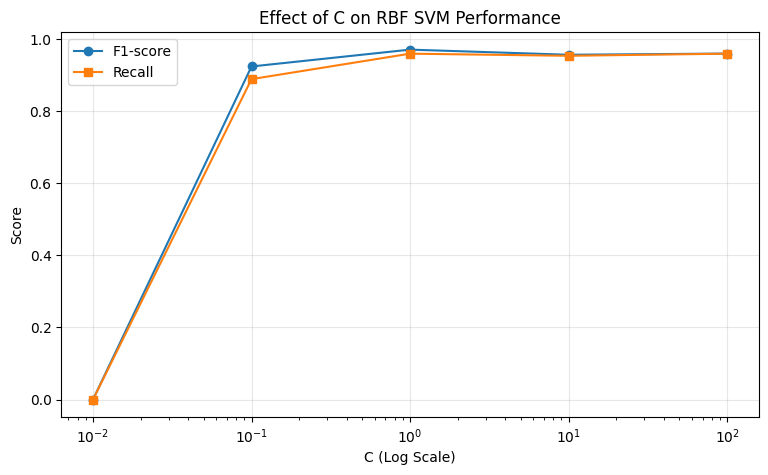

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(
    c_results['C'],
    c_results['F1'],
    marker='o',
    label='F1-score'
)

plt.plot(
    c_results['C'],
    c_results['Recall'],
    marker='s',
    label='Recall'
)

plt.xscale('log')

plt.xlabel('C (Log Scale)')
plt.ylabel('Score')
plt.title('Effect of C on RBF SVM Performance')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [29]:
gamma_values = [0.001, 0.01, 0.1, 1, 10]
gamma_results = []

for gamma in gamma_values:

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(
            kernel='rbf',
            C=1,
            gamma=gamma
        ))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1']
    )

    gamma_results.append({
        'Gamma': gamma,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean()
    })

gamma_results = pd.DataFrame(gamma_results)

print(gamma_results.round(4))

    Gamma  Accuracy  Precision  Recall      F1
0   0.001    0.9473     1.0000  0.8588  0.9239
1   0.010    0.9714     0.9820  0.9412  0.9607
2   0.100    0.9538     0.9323  0.9471  0.9387
3   1.000    0.6308     0.4000  0.0118  0.0229
4  10.000    0.6264     0.0000  0.0000  0.0000


C:\Users\Koosha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Koosha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Koosha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

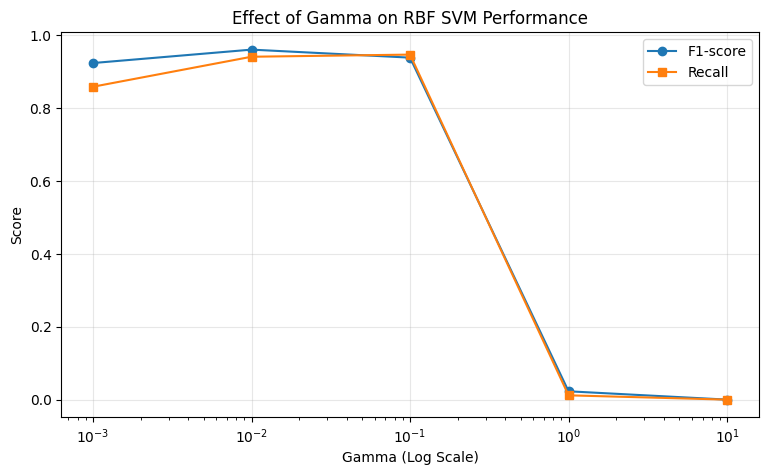

In [30]:
plt.figure(figsize=(9, 5))

plt.plot(
    gamma_results['Gamma'],
    gamma_results['F1'],
    marker='o',
    label='F1-score'
)

plt.plot(
    gamma_results['Gamma'],
    gamma_results['Recall'],
    marker='s',
    label='Recall'
)

plt.xscale('log')
plt.xlabel('Gamma (Log Scale)')
plt.ylabel('Score')
plt.title('Effect of Gamma on RBF SVM Performance')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Decision Boundary Visualization (2D Projection)
To illustrate how the tuned RBF kernel (`C=1, gamma=0.01`) partitions feature space, a 2D model is fitted on `mean radius` and `mean texture`. The resulting contour plot demonstrates a smooth, non-linear decision boundary separating lower-radius/lower-texture benign clusters from larger, irregular malignant tumors without overfitting individual outliers.

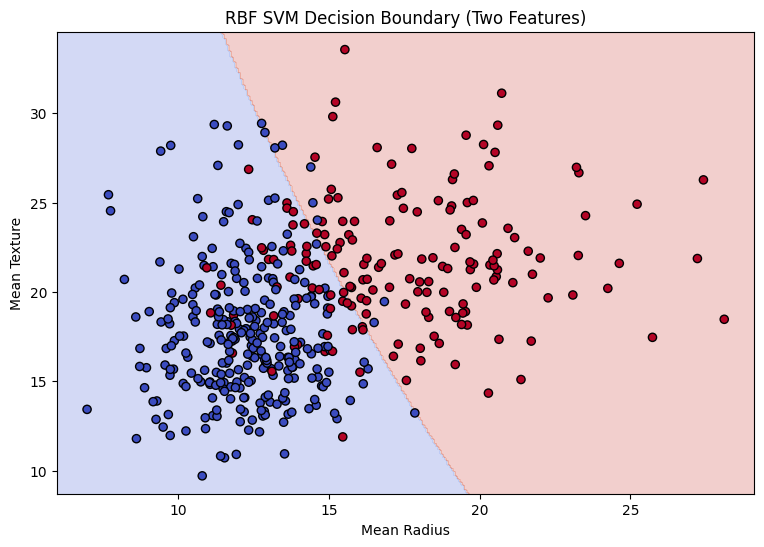

In [31]:
features = ['mean radius', 'mean texture']

X_train_2d = X_train[features]
y_train_2d = y_train

# Train RBF SVM using the selected parameters
model_2d = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1, gamma=0.01))
])

model_2d.fit(X_train_2d, y_train_2d)

# Create a mesh grid
x_min, x_max = X_train_2d.iloc[:, 0].min() - 1, X_train_2d.iloc[:, 0].max() + 1
y_min, y_max = X_train_2d.iloc[:, 1].min() - 1, X_train_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features
)

Z = model_2d.predict(grid)
Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')
plt.scatter(
    X_train_2d.iloc[:, 0],
    X_train_2d.iloc[:, 1],
    c=y_train_2d,
    cmap='coolwarm',
    edgecolors='k',
    s=35
)

plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.title('RBF SVM Decision Boundary (Two Features)')
plt.show()

## Final Model Evaluation & Generalization Check
The final **RBF SVM** (`C=1, gamma=0.01`) is trained on the full scaled training set and evaluated against both training and unseen test sets:

* **Training Set (`n=455`):** `Accuracy = 0.98`, `Malignant F1 = 0.98` (`Precision = 0.99`, `Recall = 0.96`)
* **Test Set (`n=114`):** `Accuracy = 0.9912`, `Malignant F1 = 0.9880` (`Precision = 1.0000`, `Recall = 0.9762`)

In [32]:
final_rbf = SVC(
    kernel='rbf',
    C=1,
    gamma=0.01
)

final_rbf.fit(X_train_scaled, y_train)

y_pred_final_rbf = final_rbf.predict(X_test_scaled)

print(classification_report(y_test, y_pred_final_rbf))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99        72
           1       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



In [33]:
y_pred_train = final_rbf.predict(X_train_scaled)

print("Train Performance:")
print(classification_report(y_train, y_pred_train))

print("Test Performance:")
print(classification_report(y_test, y_pred_final_rbf))

Train Performance:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       285
           1       0.99      0.96      0.98       170

    accuracy                           0.98       455
   macro avg       0.98      0.98      0.98       455
weighted avg       0.98      0.98      0.98       455

Test Performance:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99        72
           1       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



## Final Model Comparison Summary (Test Set)

| Model | Accuracy | Precision | Recall | F1-Score |
| :--- | :---: | :---: | :---: | :---: |
| **Linear SVM (`C=1`)** | `0.9386` | `0.8889` | `0.9524` | `0.9195` |
| **RBF SVM (`C=1, gamma=0.01`)** | **`0.9912`** | **`1.0000`** | **`0.9762`** | **`0.9880`** |
| **Polynomial SVM (`C=1, degree=3`)** | `0.9386` | `1.0000` | `0.8333` | `0.9091` |

In [34]:
models = {
    'Linear SVM': y_pred_linear,
    'RBF SVM': y_pred_final_rbf,
    'Polynomial SVM': y_pred_poly
}

comparison = []

for name, predictions in models.items():
    comparison.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4))

            Model  Accuracy  Precision  Recall      F1
0      Linear SVM    0.9386     0.8889  0.9524  0.9195
1         RBF SVM    0.9912     1.0000  0.9762  0.9880
2  Polynomial SVM    0.9386     1.0000  0.8333  0.9091


**Conclusion:** The tuned **RBF SVM (`C=1, gamma=0.01`)** eliminates overfitting (closely aligned train and test metrics) and achieves `99.12%` test accuracy with `100%` precision and `97.62%` recall on malignant cases, misclassifying only 1 out of 42 malignant samples in the holdout set.